1. Data preprocessing
Dataset Iris memiliki 150 sampel, empat fitur numerik dalam cm dan tiga kelas seimbang. Langkah: cek data kosong/duplikat, pisahkan X dan y, lalu stratified split 80:20.

In [ ]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

iris = load_iris(as_frame=True)
X, y = iris.data.copy(), iris.target.copy()
print('Versi scikit-learn:', sklearn.__version__)
print('Jumlah data:', len(X), '| Jumlah fitur:', X.shape[1])
print('Nilai kosong:', int(X.isna().sum().sum()))
print('Baris fitur duplikat:', int(X.duplicated().sum()), '(ditinjau, tidak dihapus otomatis)')
print('Distribusi kelas:', dict(zip(iris.target_names, y.value_counts().sort_index())))
print('Nama fitur:', list(X.columns))

Versi scikit-learn: 1.6.1
Jumlah data: 150 | Jumlah fitur: 4
Nilai kosong: 0
Baris fitur duplikat: 1 (ditinjau, tidak dihapus otomatis)
Distribusi kelas: {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}
Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f'Data training: {len(X_train)} | Data testing: {len(X_test)}')
print('Distribusi training:', y_train.value_counts().sort_index().to_dict())
print('Distribusi testing :', y_test.value_counts().sort_index().to_dict())

Data training: 120 | Data testing: 30
Distribusi training: {0: 40, 1: 40, 2: 40}
Distribusi testing : {0: 10, 1: 10, 2: 10}


2. Modeling dan hyperparameter tuning

Algoritma yang dibandingkan: KNN, Decision Tree, Random Forest, dan Logistic Regression.

In [ ]:
models = {
    'KNN': (
        Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier())]),
        {'model__n_neighbors': [3, 5, 7, 9],
         'model__weights': ['uniform', 'distance'],
         'model__p': [1, 2]}
    ),
    'Decision Tree': (
        Pipeline([('scaler', 'passthrough'), ('model', DecisionTreeClassifier(random_state=42))]),
        {'model__max_depth': [2, 3, 5],
         'model__min_samples_leaf': [1, 2, 4]}
    ),
    'Random Forest': (
        Pipeline([('scaler', 'passthrough'), ('model', RandomForestClassifier(random_state=42))]),
        {'model__n_estimators': [50, 100],
         'model__max_depth': [3, None],
         'model__min_samples_leaf': [1, 2]}
    ),
    'Logistic Regression': (
        Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=2000, random_state=42))]),
        {'model__C': [0.01, 0.1, 1.0, 10.0]}
    )
}

In [ ]:
# GridSearchCV di-fit HANYA pada training data.
searches = {}
rows = []
for name, (pipe, params) in models.items():
    search = GridSearchCV(pipe, params, scoring='f1_macro', cv=cv, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    train_pred = search.predict(X_train)
    test_pred = search.predict(X_test)
    train_f1 = f1_score(y_train, train_pred, average='macro')
    test_f1 = f1_score(y_test, test_pred, average='macro')
    ix = search.best_index_
    rows.append({
        'Algoritma': name,
        'CV F1': search.best_score_,
        'CV Std': search.cv_results_['std_test_score'][ix],
        'Train F1': train_f1,
        'Test F1': test_f1,
        'Gap F1': abs(train_f1 - test_f1),
        'Train Acc': accuracy_score(y_train, train_pred),
        'Test Acc': accuracy_score(y_test, test_pred),
    })
    print(f'{name}: best={search.best_params_} | CV F1={search.best_score_:.3f}')

KNN: best={'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'uniform'} | CV F1=0.967
Decision Tree: best={'model__max_depth': 3, 'model__min_samples_leaf': 1} | CV F1=0.958
Random Forest: best={'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__n_estimators': 100} | CV F1=0.966
Logistic Regression: best={'model__C': 10.0} | CV F1=0.966


3. Evaluasi dan perbandingan model


In [ ]:
hasil = pd.DataFrame(rows).sort_values('CV F1', ascending=False, kind='stable').reset_index(drop=True)
print('Tabel perbandingan model (angka dibulatkan):')
print(hasil.round(3).to_string(index=False))

# Tentukan pilihan BERDASARKAN CV training saja, bukan test.
selected_name = hasil.loc[0, 'Algoritma']
selected_model = searches[selected_name].best_estimator_
print()
print('Model terpilih berdasarkan CV F1 tertinggi:', selected_name)

Tabel perbandingan model (angka dibulatkan):
          Algoritma  CV F1  CV Std  Train F1  Test F1  Gap F1  Train Acc  Test Acc
                KNN  0.967   0.017     0.958    0.933   0.026      0.958     0.933
      Random Forest  0.966   0.032     0.975    0.967   0.008      0.975     0.967
Logistic Regression  0.966   0.032     0.975    1.000   0.025      0.975     1.000
      Decision Tree  0.958   0.027     0.983    0.967   0.017      0.983     0.967

Model terpilih berdasarkan CV F1 tertinggi: KNN


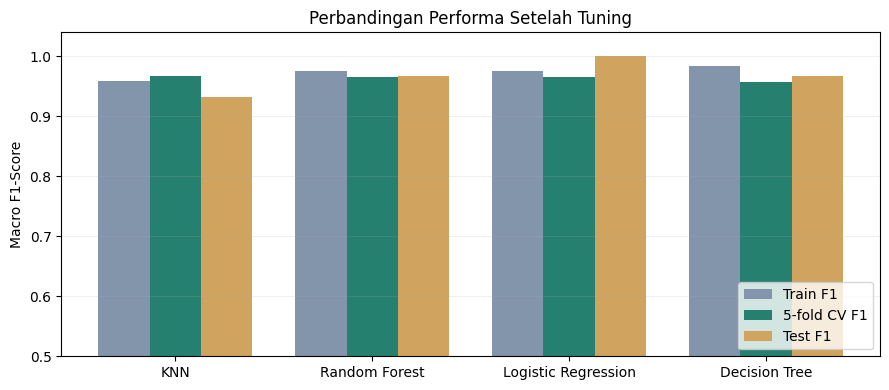

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
names = hasil['Algoritma'].tolist()
pos = np.arange(len(names))
w = 0.26
ax.bar(pos-w, hasil['Train F1'], width=w, label='Train F1', color='#8295AB')
ax.bar(pos, hasil['CV F1'], width=w, label='5-fold CV F1', color='#26806F')
ax.bar(pos+w, hasil['Test F1'], width=w, label='Test F1', color='#D0A35F')
ax.set_xticks(pos, names)
ax.set_ylim(0.5, 1.04)
ax.set_ylabel('Macro F1-Score')
ax.set_title('Perbandingan Performa Setelah Tuning')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.18)
plt.tight_layout()
plt.show()

4. Analisis good fit

In [ ]:
def diagnosis(row):
    if row['CV F1'] >= .90 and row['Test F1'] >= .90 and row['Gap F1'] <= .10:
        return 'GOOD FIT (heuristik)'
    if row['Gap F1'] > .10 and row['Train F1'] > row['Test F1']:
        return 'Periksa OVERFITTING'
    if row['CV F1'] < .90 and row['Train F1'] < .90:
        return 'Periksa UNDERFITTING'
    return 'Perlu evaluasi lanjut'

hasil['Diagnosis'] = hasil.apply(diagnosis, axis=1)
print(hasil[['Algoritma', 'CV F1', 'Train F1', 'Test F1', 'Gap F1', 'Diagnosis']].round(3).to_string(index=False))
selected_row = hasil[hasil['Algoritma'] == selected_name].iloc[0]
print()
print('KESIMPULAN:')
print('Model terpilih dari CV:', selected_name)
print('Diagnosis generalisasi:', selected_row['Diagnosis'])
print('Gunakan data tambahan / pengujian berulang jika hendak dipakai di luar dataset Iris.')

          Algoritma  CV F1  Train F1  Test F1  Gap F1            Diagnosis
                KNN  0.967     0.958    0.933   0.026 GOOD FIT (heuristik)
      Random Forest  0.966     0.975    0.967   0.008 GOOD FIT (heuristik)
Logistic Regression  0.966     0.975    1.000   0.025 GOOD FIT (heuristik)
      Decision Tree  0.958     0.983    0.967   0.017 GOOD FIT (heuristik)

KESIMPULAN:
Model terpilih dari CV: KNN
Diagnosis generalisasi: GOOD FIT (heuristik)
Gunakan data tambahan / pengujian berulang jika hendak dipakai di luar dataset Iris.


Classification report model terpilih: KNN
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Confusion matrix (baris: aktual, kolom: prediksi):
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


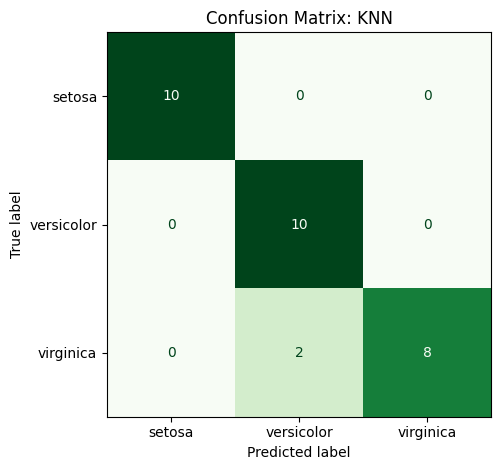

In [ ]:
pred = selected_model.predict(X_test)
print('Classification report model terpilih:', selected_name)
print(classification_report(y_test, pred, target_names=iris.target_names, digits=3))
print('Confusion matrix (baris: aktual, kolom: prediksi):')
print(confusion_matrix(y_test, pred))

fig, ax = plt.subplots(figsize=(6.3, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=iris.target_names,
    cmap='Greens', colorbar=False, ax=ax
)
ax.set_title(f'Confusion Matrix: {selected_name}')
plt.tight_layout()
plt.show()